# 01: Corpus Ingestion, 8-Stage NLP Pipeline & Bangladesh NER
**NeuroSym-BD: Neuro-Symbolic Conflict Event Extraction & Reasoning**

This notebook walks through the data ingestion and NLP extraction stages:
1. **Raw News Ingestion**: Inspecting raw crawled articles from *The Daily Star*.
2. **Relevance Filtering**: Lexical trigger matching to filter violence reports.
3. **Bangladesh-Specific NER**: Identifying political parties, security forces, and armed groups.
4. **Trigger & Argument Extraction**: Parsing violence verbs and binding subject/object roles.
5. **CAMEO Classification**: Mapping triggers to CAMEO taxonomy (roots and leaf codes).
6. **Temporal & Geospatial Normalisation**: Resolving relative dates to ISO 8601 and matching against a 64-district gazetteer.
7. **Structured EventRecord Output**: End-to-end extraction with PROV-O text offsets.


In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

cur = Path.cwd().resolve()
while cur != cur.parent:
    if (cur / "requirements.txt").exists():
        break
    cur = cur.parent
PROJECT_ROOT = cur
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/rohansmac/Documents/ml-research/neuro-symbolic-ai-workspace


## 1. Raw Crawled Articles Inspection
We inspect the ingested news articles stored in `data/raw/`.


In [2]:
raw_dir = PROJECT_ROOT / "data" / "raw"
raw_files = sorted(raw_dir.glob("*.json"))
print(f"Total raw article JSON files in {raw_dir}: {len(raw_files)}")

# Sample article
sample_file = raw_files[0] if raw_files else None
if sample_file:
    sample_article = json.loads(sample_file.read_text(encoding="utf-8"))
    print(f"\nSample Article File: {sample_file.name}")
    print(f"Title: {sample_article.get('title')}")
    print(f"URL:   {sample_article.get('url')}")
    print(f"Date:  {sample_article.get('publish_date') or sample_article.get('date')}")
    text_snippet = sample_article.get('text', '')[:300]
    print(f"Snippet: {text_snippet}...")


Total raw article JSON files in /Users/rohansmac/Documents/ml-research/neuro-symbolic-ai-workspace/data/raw: 0


## 2. 8-Stage NLP Pipeline Demonstration
We run the extraction pipeline on representative sentences to observe intermediate representations.


In [3]:
from scraper.schema import Article
from nlp.relevance_filter import keyword_filter
from nlp.ner import extract_entities
from nlp.event_triggers import detect_triggers
from nlp.cameo_classifier import classify_event
from nlp.pipeline import process_article, DEFAULT_CONFIG

test_sentence = "At least eight people were injured yesterday when Awami League and BNP supporters clashed in Pabna."

# 1. Relevance Filter
filt_res = keyword_filter(test_sentence)
print(f"1. Violence Relevant: {filt_res.verdict} (Confidence={filt_res.confidence:.2f}, Signals={filt_res.signals})")

# 2. NER
ents = extract_entities(test_sentence)
print(f"2. Extracted Entities: {ents}")

# 3. Event Triggers
trigs = detect_triggers(test_sentence)
print(f"3. Extracted Triggers: {trigs}")

# 4. CAMEO Classifier
cameo_res = classify_event(trigs[0], test_sentence, use_model=False)
print(f"4. CAMEO Classification: Code={cameo_res.cameo_code} ({cameo_res.cameo_label}), Conf={cameo_res.confidence}")

# 5. Full Pipeline Run on Article
art = Article(
    url="https://www.thedailystar.net/sample",
    title="Eight injured in Pabna clash",
    published_date="2026-10-24T10:00:00+06:00",
    body=test_sentence,
)
ev_records = process_article(art, config=DEFAULT_CONFIG)
print(f"5. End-to-end Processed Events: {len(ev_records)}")
for e in ev_records:
    print(f"   Event ID: {e.event_id} | CAMEO: {e.cameo_code} ({e.cameo_label})")


1. Violence Relevant: Verdict.VIOLENCE (Confidence=0.60, Signals=['injured', 'clashed'])


spaCy models not found. Using gazetteer regex NER fallback.


spaCy model not found (run: python -m spacy download en_core_web_sm). Using regex trigger extraction fallback.


spaCy models not found. Using regex argument extraction fallback.


2. Extracted Entities: [Entity(text='Awami League', label='POLITICAL_PARTY', canonical='Awami League', start=50, end=62, confidence=0.7), Entity(text='BNP', label='POLITICAL_PARTY', canonical='BNP', start=67, end=70, confidence=0.7)]
3. Extracted Triggers: [TriggerSpan(text='clashed', lemma='clash', start=82, end=89, cameo_code='145', kind='verb', sentence='', sentence_id=-1)]
4. CAMEO Classification: Code=145 (Engage in violent protest or rioting), Conf=0.7
5. End-to-end Processed Events: 1
   Event ID: evt_3cc29a7f_000 | CAMEO: 145 (Engage in violent protest or rioting)


## 3. Full Extracted Events Corpus
We inspect the consolidated processed events in `data/processed/events.json`.


Total structured event records extracted: 88


,Event ID,CAMEO Code,Label,District,Date,Confidence,Source URL
0,evt_bc55c6d2_000,182,"Physically assault — killing, assault, torture",None,None,0.70,https://www.thedailystar.net/news/crime-justic...
1,evt_bc55c6d2_001,182,"Physically assault — killing, assault, torture",None,None,0.70,https://www.thedailystar.net/news/crime-justic...
2,evt_ba5083c7_000,191,Impose blockade or restrict movement,Rangamati,2026-10-24,0.70,https://www.thedailystar.net/news/crime-justic...
3,evt_ba5083c7_001,182,"Physically assault — killing, assault, torture",Rangamati,2026-10-24,0.70,https://www.thedailystar.net/news/crime-justic...
4,evt_ba5083c7_002,191,Impose blockade or restrict movement,Rangamati,2026-10-24,0.70,https://www.thedailystar.net/news/crime-justic...
5,evt_ba5083c7_003,191,Impose blockade or restrict movement,Rangamati,2026-10-24,0.70,https://www.thedailystar.net/news/crime-justic...
6,evt_ba5083c7_004,193,Fight with small arms or light weapons,Rangamati,2026-10-24,0.70,https://www.thedailystar.net/news/crime-justic...
7,evt_ba5083c7_005,191,Impose blockade or restrict movement,Rangamati,2026-10-24,0.70,https://www.thedailystar.net/news/crime-justic...
8,evt_8c19e89a_000,182,"Physically assault — killing, assault, torture",None,2026-10-24,0.85,https://www.thedailystar.net/news/crime-justic...
9,evt_8c19e89a_001,182,"Physically assault — killing, assault, torture",None,2026-10-24,0.85,https://www.thedailystar.net/news/crime-justic...


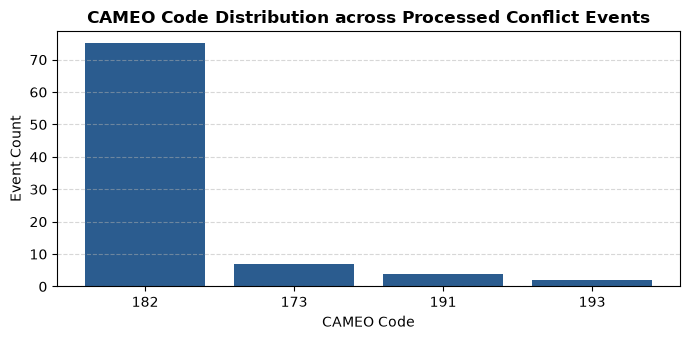

In [4]:
events_path = PROJECT_ROOT / "data" / "processed" / "events.json"
events = json.loads(events_path.read_text(encoding="utf-8"))
print(f"Total structured event records extracted: {len(events)}")

df_events = []
for ev in events:
    df_events.append({
        "Event ID": ev.get("event_id"),
        "CAMEO Code": ev.get("cameo_code"),
        "Label": ev.get("cameo_label"),
        "District": ev.get("district") or ev.get("location", {}).get("district"),
        "Date": ev.get("date", {}).get("normalized") if isinstance(ev.get("date"), dict) else ev.get("date"),
        "Confidence": ev.get("confidence"),
        "Source URL": ev.get("source_url") or ev.get("article_url"),
    })

df_ev = pd.DataFrame(df_events)
display(df_ev.head(10))

# CAMEO Code Distribution Plot
plt.figure(figsize=(7, 3.5))
code_counts = df_ev["CAMEO Code"].value_counts()
plt.bar([str(c) for c in code_counts.index], code_counts.values, color="#2b5c8f")
plt.title("CAMEO Code Distribution across Processed Conflict Events", fontweight="bold")
plt.xlabel("CAMEO Code")
plt.ylabel("Event Count")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
